# 有监督学习 vs 无监督学习 —— 核心区别笔记

## 总览对比表

| 维度 | 有监督学习 (Supervised Learning) | 无监督学习 (Unsupervised Learning) |
| :--- | :--- | :--- |
| **数据标签** | 有标签（Label）。数据由 `(x, y)` 组成，其中 `y` 是人为标注的“标准答案”。 | 无标签（No Label）。数据仅为 `(x)`，没有预设的 `y`。 |
| **核心目标** | **预测 / 映射**。学习从输入 `x` 到输出 `y` 的映射关系（决策边界）。 | **发现 / 描述**。发现数据 `x` 内部隐藏的结构、分布或关联规则。 |
| **任务类型** | - **回归**（预测房价、温度）<br>- **分类**（识别猫狗、垃圾邮件过滤） | - **聚类**（用户分群）<br>- **降维**（特征压缩）<br>- **关联规则**（购物篮分析） |
| **反馈机制** | **显式反馈**。模型预测错误时，损失函数（如交叉熵、MSE）会直接给出惩罚，引导模型修正。 | **隐式反馈**。没有“对错”，只有“合理”与否（如聚类紧密度、重构误差最小化）。 |
| **评估指标** | 客观明确（准确率、精确率、召回率、RMSE）。 | 主观且依赖业务（轮廓系数、困惑度，或仅用于定性观察）。 |

---

## 关键记忆点

- **有监督 = 有标准答案的“练习题”**，目标是最小化预测与答案之间的误差。
- **无监督 = 没有答案的“探索题”**，目标是挖掘数据自身的规律。
- 两者本质区别在于**是否使用标签信息**，但在实际项目中常组合使用（如半监督学习、自监督学习）。

### 聚类算法
聚类用于将样本根据相似性分类，算法将样本点划分为多个簇，使得同一簇内的样本点相似度高，不同簇间的样本点相似度低
项目初期使用较多，没有先验知识（标签）时使用聚类，否则就会转为分类

- 聚类算法没有任何标签，唯一的判断依据是“距离”。距离越近，越相似。
- 必须进行标准化，否则量纲大的特征会完全覆盖量纲小的特征，同逻辑回归

### 1. 欧氏距离（Euclidean Distance）  最常用

**直觉**：两点之间的直线距离（最常见的距离），对应维度差值平方和，开平方根。

**公式（二维）：**
$$
d = \sqrt{(x_1 - y_1)^2 + (x_2 - y_2)^2}
$$

**公式（n 维）：**
$$
d(\mathbf{x}, \mathbf{y}) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}
$$
### 2. 曼哈顿距离（Manhattan Distance）

**直觉**：只能沿坐标轴方向移动的距离，如同在曼哈顿街区从 A 点走到 B 点。
         也称"城市街区距离"，对应维度差值的绝对值，求和。

**公式：**
$$
d(\mathbf{x}, \mathbf{y}) = \sum_{i=1}^{n} |x_i - y_i|
$$


### K—均值聚类
**核心思想**
将平面（或空间）中的点划分为K个簇，使得每个点距离其所属簇的中心点（质心）的距离平方和最小
$$
J = \sum_{k=1}^K\sum_{x_i∈C_k}||x_i - μ_k||^2
$$
线性回归最小化的是真实值到预测线的垂直距离平方和（MSE）
K-Means 最小化的是样本点到质心点的欧氏距离平方和
- 目标函数在大数据样本下无法直接求解，只能依靠迭代逼近（坐标下降法）

**核心流程**
- 初始化：随机挑选K个样本点作为初始值
- 分配：计算每个样本到质心的欧氏距离，将其归类到离他最近的质心所代表的簇
- 更新：对于每个簇，更新簇内样本的均值，将质心移动到均值位置

**确定k值**
- 轮廓系数 $s = \frac{b-a}{max(a,b)}$,计算不同K下的平均轮廓系数，选择使平均轮廓系数最高的k
- 肘部法则 计算不同K值下的惯性，选择曲线急剧下降（簇越多，样本离质心越近）后变得平缓的拐点，作为k值

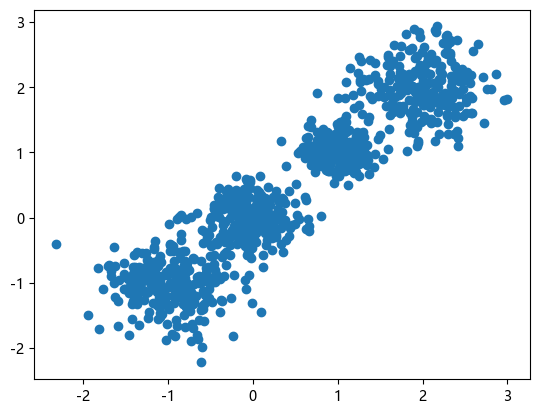

C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


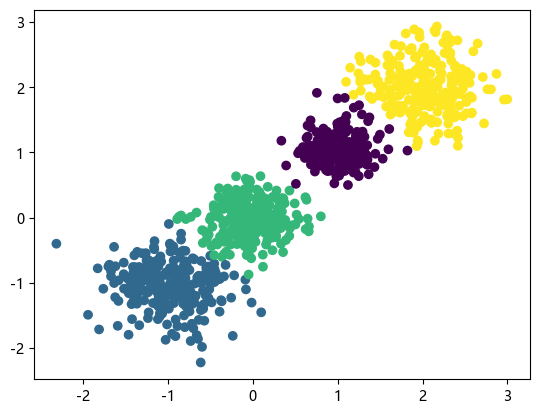

评价指标(评分): 4116.275372994925


In [5]:
from sklearn.metrics import calinski_harabasz_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs  # 按照高斯分布生成数据集

# 聚类算法没有标签，y代表样本所属的簇
x,y = make_blobs(n_samples=1000, # 样本总数，可传入数组指定每个簇的样本数
    n_features=2,                # 特征数量，即每个样本点的维度，2是二维平面
    centers=[[-1,-1],[0,0],[1,1],[2,2]],                   # 簇中心个数，即指定生成簇的个数
    cluster_std=[0.41,0.3,0.2,0.4],             # 簇的标准差
    random_state=10)

plt.scatter(x[:,0],x[:,1])
plt.show()

estimator = KMeans(n_clusters=4,random_state=10)
y_pred = estimator.fit_predict(x)
plt.scatter(x[:,0],x[:,1],c=y_pred)
plt.show()

# 聚类算法评价指标 越大聚类效果越好
print(f"评价指标(评分): {calinski_harabasz_score(x,y_pred)}")

C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than avai

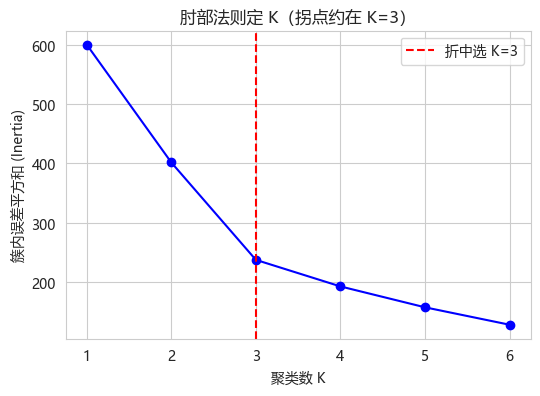

C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


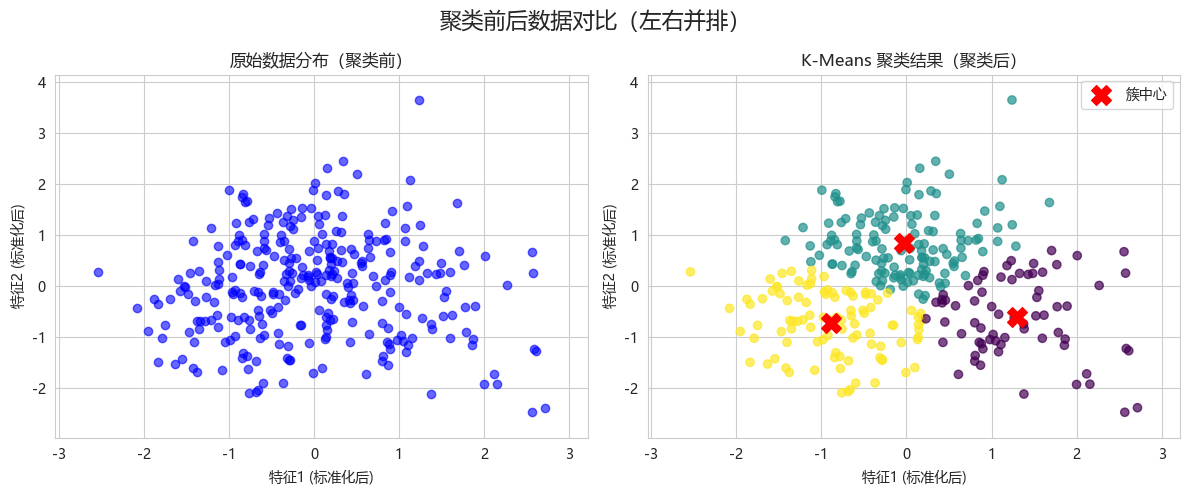

各簇中心坐标（标准化后）：
梯队 1: [ 1.297 -0.61 ]
梯队 2: [-0.029  0.838]
梯队 3: [-0.883 -0.724]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_blobs

plt.rc('font', **{'family': 'Microsoft YaHei, SimHei'})
plt.rcParams['axes.unicode_minus'] = False

# 1. 生成重叠较多的数据
X, _ = make_blobs(n_samples=300, 
                  centers=[[-1.5, 0], [1.5, 0], [0, 1.8]],
                  cluster_std=[1.2, 1.5, 1.0],
                  random_state=42)

# 标准化
X_scaled = StandardScaler().fit_transform(X)

# 2. 肘部法则（不变，仍单独展示）
inertias = []
K_range = range(1, 7)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(K_range, inertias, 'bo-')
plt.xlabel('聚类数 K')
plt.ylabel('簇内误差平方和 (Inertia)')
plt.title('肘部法则定 K（拐点约在 K=3）')
plt.axvline(x=3, color='r', linestyle='--', label='折中选 K=3')
plt.legend()
plt.show()

# 3. 执行 K-Means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
y_pred = kmeans.fit_predict(X_scaled)

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 5))

ax_left.scatter(X_scaled[:, 0], X_scaled[:, 1], alpha=0.6, color='blue')
ax_left.set_title('原始数据分布（聚类前）', fontsize=12)
ax_left.set_xlabel('特征1 (标准化后)')
ax_left.set_ylabel('特征2 (标准化后)')
# 固定坐标轴范围，与右图保持一致，便于对比
x_min, x_max = X_scaled[:, 0].min() - 0.5, X_scaled[:, 0].max() + 0.5
y_min, y_max = X_scaled[:, 1].min() - 0.5, X_scaled[:, 1].max() + 0.5
ax_left.set_xlim(x_min, x_max)
ax_left.set_ylim(y_min, y_max)


# 按簇着色
scatter = ax_right.scatter(X_scaled[:, 0], X_scaled[:, 1], 
                           c=y_pred, cmap='viridis', alpha=0.7)
# 绘制簇中心
ax_right.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
                 marker='X', s=200, c='red', label='簇中心')
ax_right.set_title('K-Means 聚类结果（聚类后）', fontsize=12)
ax_right.set_xlabel('特征1 (标准化后)')
ax_right.set_ylabel('特征2 (标准化后)')
ax_right.set_xlim(x_min, x_max)
ax_right.set_ylim(y_min, y_max)
ax_right.legend()

# 添加总标题
fig.suptitle('聚类前后数据对比（左右并排）', fontsize=16)

# 调整布局，防止标签重叠
plt.tight_layout()
plt.show()

# 输出簇中心（不变）
print("各簇中心坐标（标准化后）：")
for i, center in enumerate(kmeans.cluster_centers_):
    print(f"梯队 {i+1}: {center.round(3)}")

### 层次聚类（Hierarchical）
凝聚式（Agglomerative 自底向上） 主流
初始时把每个样本当成一个独立的簇，每次找距离最近的两个簇合并，直到所有样本合并成一个大簇，无需输入k值

**核心流程**
- 初始化：每个样本看作一个单独的簇
- 计算距离矩阵：计算每两个簇之间的距离
- 合并（贪心）：找出距离矩阵中距离最近的两个簇，将其合并成一个新簇
- 更新与迭代：更新距离矩阵，知道所有样本合成一个大簇

**确认K值**
层次聚类无需输入K值，其产出的是一棵树状图（Dendrogram），横轴是样本，纵轴是合并时的距离（或差异度）
在树状图某个合适的“高度”横切一刀，切刀下方形成的独立树枝个数，即使划分的簇数
- 切得低：细分成大量小簇（类内极相似）
- 切得高：合并成几个大簇（类内差异较大）
- **工业界最佳实践**：遍历所有切分点（不同的K），计算轮廓系数，取最大的那个K作为最终方案。

**应用领域**
- **生物信息学（基因聚类）**：物种演化、基因表达谱分析——本质上就需要画“亲缘关系树”，天然适配层次聚类
- **小型探索性数据分析（EDA）**：只有几千条数据，想直观地看数据是否有天然的“巢状结构”（大群套小群）。树状图的视觉效果远胜 K-Means 的散点圈圈
- **半监督生成标签**：对少量高价值样本（如头部商家、头部用户）进行精细化分层（如“超级 VIP”、“大客户”、“普通客户”）

### 两个簇之间的距离

#### 1. 欧氏距离（Euclidean Distance）   最常用

**直觉**：两点之间的直线距离（最常见的距离），对应维度差值平方和，开平方根。

**公式（二维）：**
$$
d = \sqrt{(x_1 - y_1)^2 + (x_2 - y_2)^2}
$$

**公式（n 维）：**
$$
d(\mathbf{x}, \mathbf{y}) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}
$$

#### 2. 曼哈顿距离（Manhattan Distance）

**直觉**：只能沿坐标轴方向移动的距离，如同在曼哈顿街区从 A 点走到 B 点。
         也称"城市街区距离"，对应维度差值的绝对值，求和。

**公式：**
$$
d(\mathbf{x}, \mathbf{y}) = \sum_{i=1}^{n} |x_i - y_i|
$$

城市经济数据集（前5行）：
  AREA     Gross       Avg
0   上海  2.580766  0.613874
1   北京  2.213249  1.574349
2   深圳  3.239819  0.709020
3   广州  1.496985  0.928956
4   天津  3.338187  1.221850

数据集基本信息：
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AREA    15 non-null     object 
 1   Gross   15 non-null     float64
 2   Avg     15 non-null     float64
dtypes: float64(2), object(1)
memory usage: 492.0+ bytes
None


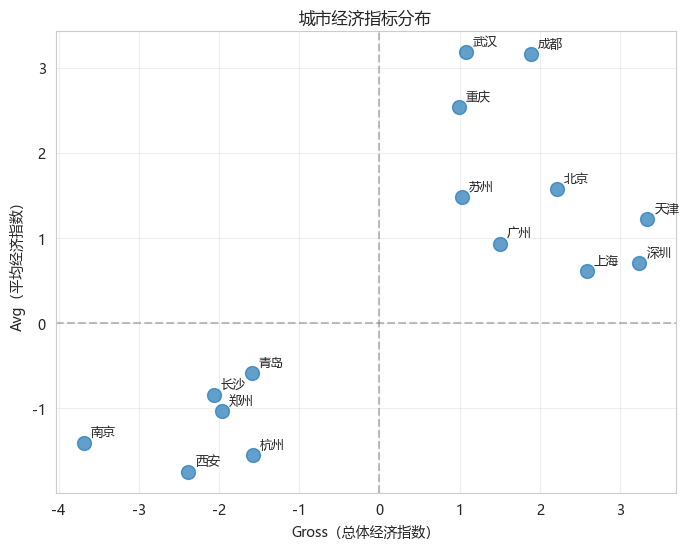

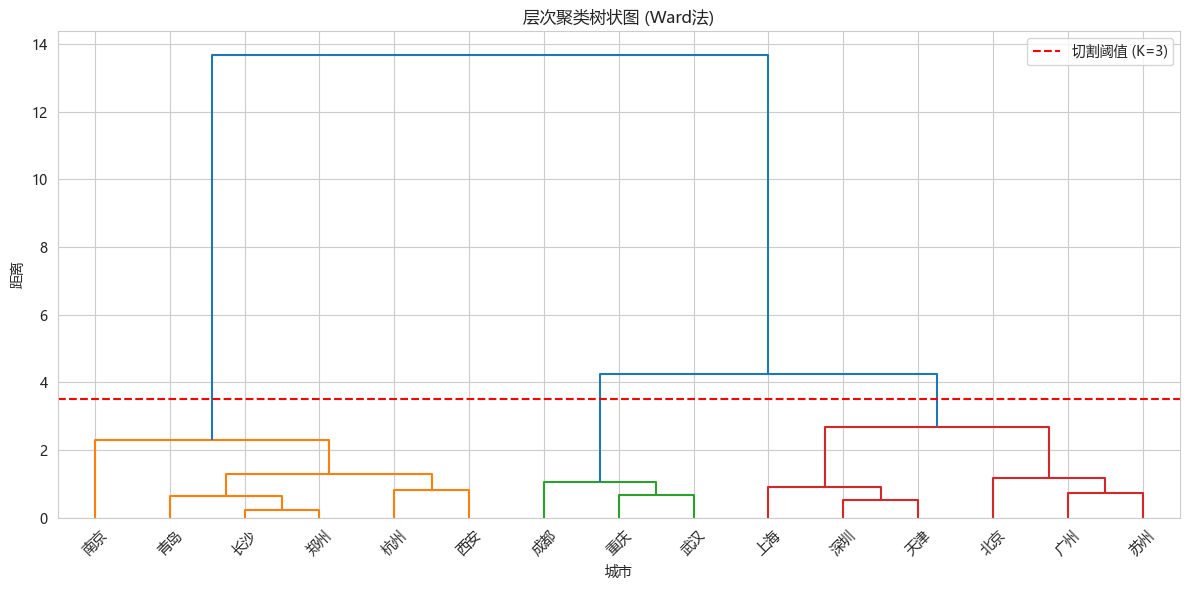


聚类结果（按距离阈值切割）：
   AREA     Gross       Avg  Cluster
0    上海  2.580766  0.613874        3
1    北京  2.213249  1.574349        3
2    深圳  3.239819  0.709020        3
3    广州  1.496985  0.928956        3
4    天津  3.338187  1.221850        3
5    重庆  0.985694  2.532740        2
6    苏州  1.024599  1.486216        3
7    成都  1.885172  3.163198        2
8    武汉  1.080794  3.187254        2
9    杭州 -1.577662 -1.545166        1
10   南京 -3.686132 -1.401968        1
11   西安 -2.383813 -1.742195        1
12   长沙 -2.062706 -0.836851        1
13   青岛 -1.592478 -0.582818        1
14   郑州 -1.967501 -1.031862        1

聚类结果（指定3个簇）：
   AREA     Gross       Avg  Cluster2
0    上海  2.580766  0.613874         1
1    北京  2.213249  1.574349         1
2    深圳  3.239819  0.709020         1
3    广州  1.496985  0.928956         1
4    天津  3.338187  1.221850         1
5    重庆  0.985694  2.532740         3
6    苏州  1.024599  1.486216         1
7    成都  1.885172  3.163198         3
8    武汉  1.080794  3.187254         

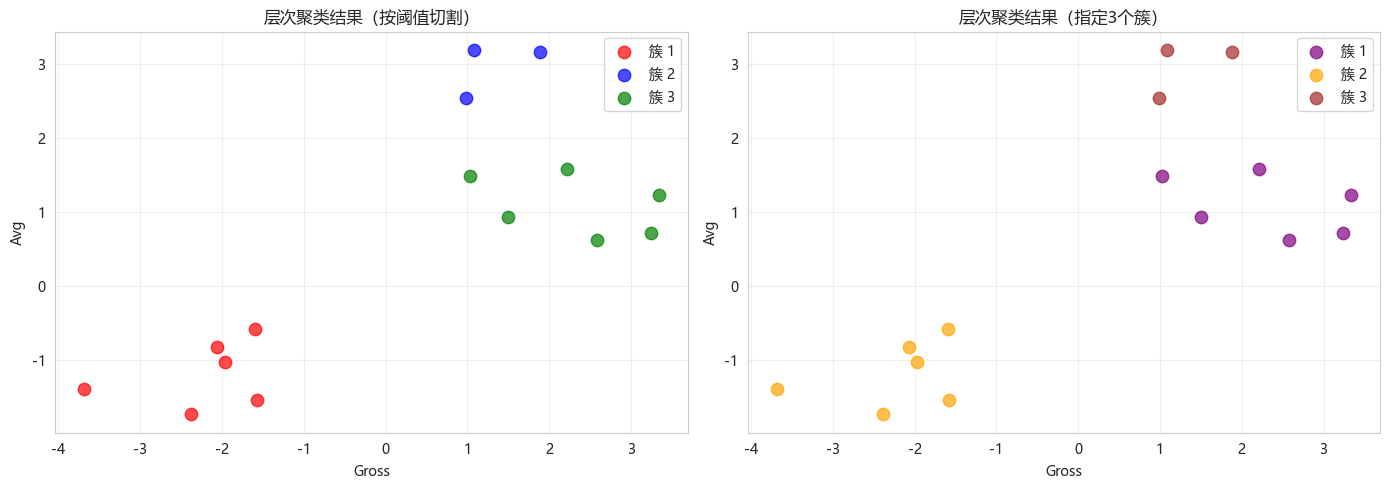


========== 聚类结果分析 ==========

簇 1：
  城市：杭州, 南京, 西安, 长沙, 青岛, 郑州
  平均 Gross：-2.212
  平均 Avg：-1.190
  城市数量：6

簇 2：
  城市：重庆, 成都, 武汉
  平均 Gross：1.317
  平均 Avg：2.961
  城市数量：3

簇 3：
  城市：上海, 北京, 深圳, 广州, 天津, 苏州
  平均 Gross：2.316
  平均 Avg：1.089
  城市数量：6


In [3]:
# 1.导入所需库 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist
from sklearn.cluster import AgglomerativeClustering


plt.rc('font', **{'family': 'Microsoft YaHei, SimHei'})
plt.rcParams['axes.unicode_minus'] = False

# 2.数据处理
df = pd.read_csv('城市经济数据.csv', encoding='utf-8-sig')
print("城市经济数据集（前5行）：")
print(df.head())
print("\n数据集基本信息：")
print(df.info())

# 3.绘制原始数据散点图
plt.figure(figsize=(8, 6))
plt.scatter(df['Gross'], df['Avg'], s=100, alpha=0.7)
for i, row in df.iterrows():
    plt.annotate(row['AREA'], (row['Gross'], row['Avg']), 
                 fontsize=9, xytext=(5, 5), textcoords='offset points')
plt.xlabel('Gross（总体经济指数）')
plt.ylabel('Avg（平均经济指数）')
plt.title('城市经济指标分布')
plt.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
plt.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
plt.grid(alpha=0.3)
plt.show()

# 4.层次聚类
# 计算距离矩阵（欧氏距离）
disMat = pdist(df[['Gross', 'Avg']], metric='euclidean')

# 进行层次聚类（使用Ward法）
Z = linkage(disMat, method='ward')

# 5.绘制树状图
plt.figure(figsize=(12, 6))
P = dendrogram(Z, labels=df['AREA'].tolist(), 
               leaf_rotation=45, leaf_font_size=10,
               color_threshold=3.5)  # 颜色阈值可根据数据调整
plt.axhline(y=3.5, color='red', linestyle='--', linewidth=1.5, label='切割阈值 (K=3)')
plt.xlabel('城市')
plt.ylabel('距离')
plt.title('层次聚类树状图 (Ward法)')
plt.legend()
plt.tight_layout()
plt.savefig('聚类结果.png', dpi=300)
plt.show()

# 6.根据阈值切割得到聚类标签
# 方法一：按距离阈值切割
threshold = 3.5
labels = fcluster(Z, t=threshold, criterion='distance')
df['Cluster'] = labels

print("\n聚类结果（按距离阈值切割）：")
print(df[['AREA', 'Gross', 'Avg', 'Cluster']])

# 方法二：直接指定聚类数（与K-Means使用方式一致）
model = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels2 = model.fit_predict(df[['Gross', 'Avg']])
df['Cluster2'] = labels2 + 1  # 转换为从1开始编号

print("\n聚类结果（指定3个簇）：")
print(df[['AREA', 'Gross', 'Avg', 'Cluster2']])

# 7.可视化聚类结果
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 左图：按阈值切割的结果
colors1 = ['red', 'blue', 'green']
for i in range(1, 4):
    mask = (df['Cluster'] == i)
    axes[0].scatter(df.loc[mask, 'Gross'], df.loc[mask, 'Avg'], 
                    c=colors1[i-1], s=80, alpha=0.7, label=f'簇 {i}')
axes[0].set_xlabel('Gross')
axes[0].set_ylabel('Avg')
axes[0].set_title('层次聚类结果（按阈值切割）')
axes[0].legend()
axes[0].grid(alpha=0.3)

# 右图：指定3个簇的结果
colors2 = ['purple', 'orange', 'brown']
for i in range(3):
    mask = (df['Cluster2'] == i+1)
    axes[1].scatter(df.loc[mask, 'Gross'], df.loc[mask, 'Avg'], 
                    c=colors2[i], s=80, alpha=0.7, label=f'簇 {i+1}')
axes[1].set_xlabel('Gross')
axes[1].set_ylabel('Avg')
axes[1].set_title('层次聚类结果（指定3个簇）')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 8.聚类结果分析结果分析 
print("\n========== 聚类结果分析 ==========")
for i in range(1, 4):
    cluster_data = df[df['Cluster'] == i]
    print(f"\n簇 {i}：")
    print(f"  城市：{', '.join(cluster_data['AREA'].tolist())}")
    print(f"  平均 Gross：{cluster_data['Gross'].mean():.3f}")
    print(f"  平均 Avg：{cluster_data['Avg'].mean():.3f}")
    print(f"  城市数量：{len(cluster_data)}")


### 密度聚类（DBSCAN）
密度聚类认为簇不是由中心定义的，而是“高密度区域”定义。
将具有足够密度的区域划分成簇，并在具有噪声的空间数据库中发现任意形状的簇，它将簇定义为密度相连的点的最大集合

**两个核心参数**
- eps 邻域半径
- minPts 最小样本数
- 如果给定对象eps邻域内的样本数大于或等于minPts，则该对象为核心对象

**三类样本**
- 核心点：半径eps内，邻居数量≥minPts，可以向外扩张
- 边界点：半径eps内，邻居数量<minPts,在某个核心点的邻域内，依附于核心点，不能独立扩张
- 噪声点：在低密度区域，被算法标记为离群点

**核心流程**
- 寻找核心点：便利所有样本，寻找所有满足“圈内邻居≥minPts”的核心点
- 密度直达：从一个核心点出发，将圈内所有点（核心点或边界点）拉入同一个簇
- 密度可达：如果圈内包含其他核心点，则继续从该核心点出发，把圈内的点打进该簇

缺点：
高维度数据会使距离失效（所有点的欧式距离都会变得很接近），此时无论 eps 调成多少，很难形成密度差异，DBSCAN 直接瘫痪。
密度不均匀的数据，如果数据集中既有极其密集的“原子核”（如闹市区），又有极其稀疏的“郊区”（如乡村），用同一个全局 eps 去衡量会导致：郊区全变成噪声，或者市区全连成一个大团。



✅ 自动提取到的特征列：['latitude', 'longitude', 'daily_rentals', 'dock_count']

=== DBSCAN 聚类结果统计 ===
估计的簇数量: 5
被标记为噪声的样本数: 42

各簇详细样本数分布：
Cluster
-1     42
 0    136
 1    144
 2    142
 3      6
Name: count, dtype: int64

=== 真实标签 vs 聚类标签 交叉表 ===
Cluster     -1    0    1    2  3  All
True_Label                           
0           14  136    0    0  0  150
1            6    0  144    0  0  150
2            2    0    0  142  6  150
3           20    0    0    0  0   20
All         42  136  144  142  6  470


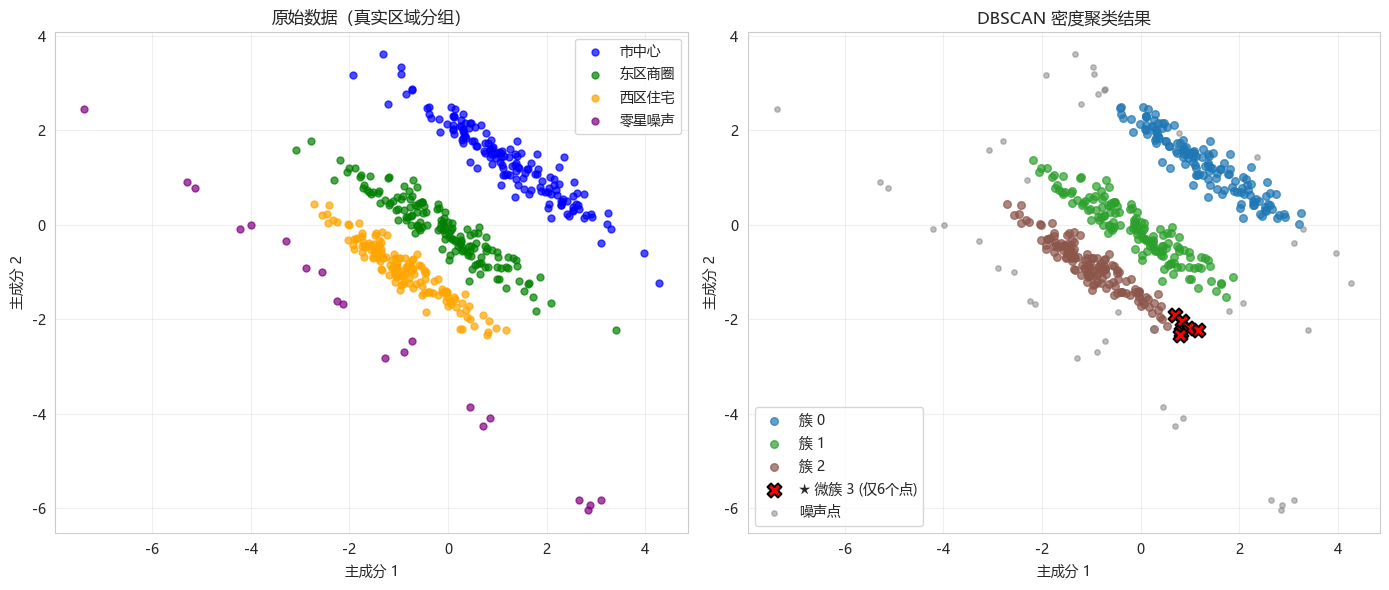


=== 各租赁点群组特征分析 ===

群组 0 (站点数: 136) 
  - 平均纬度: 39.9343
  - 平均经度: 116.4340
  - 日均租借量: 351
  - 平均车桩数: 29.9

群组 1 (站点数: 144) 
  - 平均纬度: 39.8493
  - 平均经度: 116.3860
  - 日均租借量: 219
  - 平均车桩数: 20.2

群组 2 (站点数: 142) 
  - 平均纬度: 39.8309
  - 平均经度: 116.3052
  - 日均租借量: 129
  - 平均车桩数: 15.2

群组 3 (站点数: 6) ⭐ 特殊微群组
  - 平均纬度: 40.7284
  - 平均经度: 117.2294
  - 日均租借量: 143
  - 平均车桩数: 16.8

噪声点 (站点数: 42)：这些租赁点使用模式孤立，建议实地考察是否保留。

密度聚类（DBSCAN）在本案例中的优势：
1. 自动发现任意形状的簇（不受球形限制）
2. 自动识别噪声点（偏远/异常站点）
3. 无需预先指定簇数量（参数 eps/min_samples 控制密度阈值）
4. 适合地理空间数据（密度自然定义清晰）


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA

# 设置中文字体支持
plt.rc('font', **{'family': 'Microsoft YaHei, SimHei'})
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('bike_stations.csv', encoding='utf-8-sig')

# 自动提取特征（排除标签列）
feature_names = df.select_dtypes(include=[np.number]).columns.tolist()
exclude_cols = ['True_Label', 'Cluster']
feature_names = [col for col in feature_names if col not in exclude_cols]
print(f"\n✅ 自动提取到的特征列：{feature_names}")

X = df[feature_names].values

# 4.数据标准化
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. DBSCAN密度聚类 
# - eps: 邻域半径（经标准化后，0.3 对应于实际地理距离约 0.3 个标准差）
# - min_samples: 核心点所需最小样本数（设为 5，避免小集群被当作噪声）
dbscan = DBSCAN(eps=0.4, min_samples=5)
df['Cluster'] = dbscan.fit_predict(X_scaled)

# 统计结果
n_clusters = len(set(df['Cluster'])) - (1 if -1 in df['Cluster'] else 0)
n_noise = list(df['Cluster']).count(-1)

print(f"\n=== DBSCAN 聚类结果统计 ===")
print(f"估计的簇数量: {n_clusters}")
print(f"被标记为噪声的样本数: {n_noise}")

cluster_counts = df['Cluster'].value_counts().sort_index()
print("\n各簇详细样本数分布：")
print(cluster_counts)

# 真实标签 vs 聚类标签交叉表
if 'True_Label' in df.columns:
    print("\n=== 真实标签 vs 聚类标签 交叉表 ===")
    cross_tab = pd.crosstab(df['True_Label'], df['Cluster'], margins=True)
    print(cross_tab)

# 6.可视化对比
# 使用 PCA 降维到 2D（由于经纬度本身是 2D，也可以直接绘图，但为了展示特征整合效果，仍用 PCA）
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# ---- 左子图：原始真实分组 ----
if 'True_Label' in df.columns:
    colors_true = ['blue', 'green', 'orange', 'purple']
    for label in sorted(df['True_Label'].unique()):
        mask = (df['True_Label'] == label)
        label_name = ['市中心', '东区商圈', '西区住宅', '零星噪声'][int(label)]
        ax1.scatter(X_pca[mask, 0], X_pca[mask, 1], 
                    c=colors_true[int(label)], s=25, alpha=0.7, 
                    label=label_name)
    ax1.set_title('原始数据（真实区域分组）')
    ax1.legend()
else:
    ax1.scatter(X_pca[:, 0], X_pca[:, 1], s=25, alpha=0.7)
    ax1.set_title('原始数据')
ax1.set_xlabel('主成分 1')
ax1.set_ylabel('主成分 2')
ax1.grid(alpha=0.3)

# ---- 右子图：DBSCAN 聚类结果 ----
unique_labels = set(df['Cluster'])
colors_cluster = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

# 找出真正的微簇（样本数 < 总样本的 3%）
total_samples = len(df)
min_cluster_label = None
for label in unique_labels:
    if label == -1:
        continue
    size = sum(df['Cluster'] == label)
    if size / total_samples < 0.03:
        min_cluster_label = label
        min_cluster_size = size
        break

for i, label in enumerate(unique_labels):
    mask = (df['Cluster'] == label)
    if label == -1:
        ax2.scatter(X_pca[mask, 0], X_pca[mask, 1], 
                    c='gray', s=15, alpha=0.5, label='噪声点')
    elif label == min_cluster_label:
        ax2.scatter(X_pca[mask, 0], X_pca[mask, 1], 
                    c='red', s=100, alpha=1.0, marker='X',
                    edgecolors='black', linewidths=1.5,
                    label=f'★ 微簇 {label} (仅{min_cluster_size}个点)')
    else:
        col = colors_cluster[i]
        ax2.scatter(X_pca[mask, 0], X_pca[mask, 1], 
                    c=[col], s=30, alpha=0.7, label=f'簇 {label}')

ax2.set_title('DBSCAN 密度聚类结果')
ax2.set_xlabel('主成分 1')
ax2.set_ylabel('主成分 2')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 7.结果分析与业务解读
print("\n=== 各租赁点群组特征分析 ===")
for cluster_id in sorted(set(df['Cluster'])):
    if cluster_id == -1:
        continue
    cluster_data = df[df['Cluster'] == cluster_id]
    is_minor = (cluster_id == min_cluster_label)
    print(f"\n群组 {cluster_id} (站点数: {len(cluster_data)}) {'⭐ 特殊微群组' if is_minor else ''}")
    mean_values = cluster_data[feature_names].mean()
    print(f"  - 平均纬度: {mean_values['latitude']:.4f}")
    print(f"  - 平均经度: {mean_values['longitude']:.4f}")
    print(f"  - 日均租借量: {mean_values['daily_rentals']:.0f}")
    print(f"  - 平均车桩数: {mean_values['dock_count']:.1f}")

print(f"\n噪声点 (站点数: {n_noise})：这些租赁点使用模式孤立，建议实地考察是否保留。")

# 8.密度聚类优势总结
print("\n" + "="*60)
print("密度聚类（DBSCAN）在本案例中的优势：")
print("1. 自动发现任意形状的簇（不受球形限制）")
print("2. 自动识别噪声点（偏远/异常站点）")
print("3. 无需预先指定簇数量（参数 eps/min_samples 控制密度阈值）")
print("4. 适合地理空间数据（密度自然定义清晰）")
print("="*60)

### 主成分分析 PCA
经典的无监督线性降维算法，PCA不关心类别，只关心数据在哪几个方向上的波动（方差）最大
然后将数据投影到主要方向上，实现降维
PCA认为，特征的“信息量”不取决于其平均值，而是取决于其方差。方差越大说明数据在该特征的区分度越高。
如方差为0，说明该特征毫无信息量，可以直接丢弃。

**核心流程**
- 标准化：同K-Means和逻辑回归，必须进行标准化，否则量纲大的特征会完全覆盖量纲小的特征
- 计算协方差矩阵：对角线上是每个特征的方差，非对角线元素是特征间的协方差（衡量两个随机变量的变化方向是否一致）
- 计算特征值和特征向量：特征值代表主成分的方差大小，特征值越大，说明该方向的信息量越多
- 选择主成分投影：将特征值升序排列，选出K个特征值对于的特征向量，组成投影矩阵W。W与原始1数据相乘，得到降维后的新数据  $X_{new} = X*W$

**如何确认K值**
- 解释方差比，通常累计解释方差比达到90%~95%即可
- 肘部法则，同K-Means

✅ 数据集加载成功
数据集大小: (178, 14) (178个样本, 13个特征)

前5行数据预览：
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/

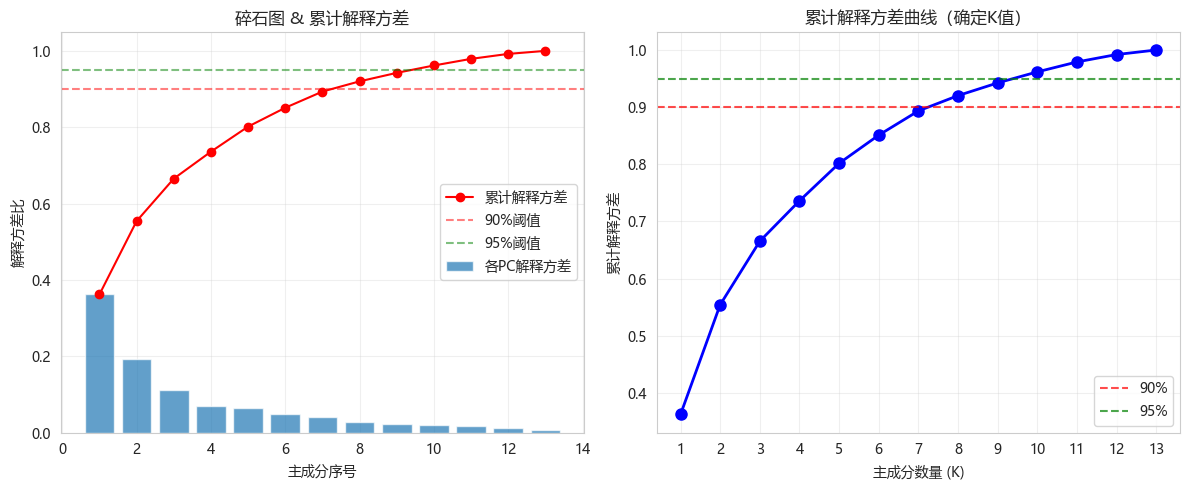


=== K值确定（基于累计解释方差） ===
达到90%累计方差需要的主成分数：K = 8
达到95%累计方差需要的主成分数：K = 10

选择 K=2 进行降维，累计解释方差：0.5541 (55.41%)


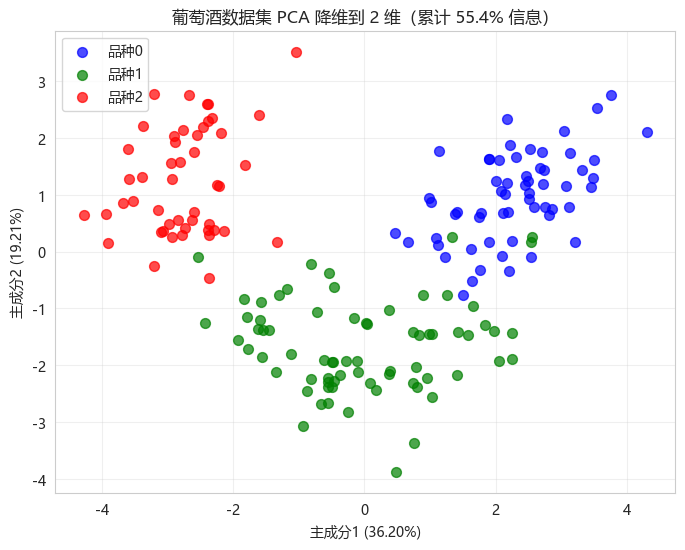


=== 主成分载荷分析（特征对PC的贡献） ===

PC1 的主要贡献特征（贡献绝对值前5）：
  flavanoids: 0.423
  total_phenols: 0.395
  od280/od315_of_diluted_wines: 0.376
  proanthocyanins: 0.313
  nonflavanoid_phenols: -0.299

PC2 的主要贡献特征（贡献绝对值前5）：
  color_intensity: 0.530
  alcohol: 0.484
  proline: 0.365
  ash: 0.316
  magnesium: 0.300
原始数据形状： (178, 13)
降维后数据形状： (178, 2)
数据压缩率：84.6% (从13维降到2维)


In [20]:
# 1.导入所需库
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine


plt.rc('font', **{'family': 'Microsoft YaHei, SimHei'})
plt.rcParams['axes.unicode_minus'] = False

# 2. 加载数据（使用sklearn自带的葡萄酒数据集）
wine = load_wine()
X = wine.data  # 特征矩阵 (178, 13)
y = wine.target  # 真实标签（3种葡萄酒品种，仅用于可视化对比）

# 特征名称
feature_names = wine.feature_names

df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

print("✅ 数据集加载成功")
print(f"数据集大小: {df.shape} (178个样本, 13个特征)")
print("\n前5行数据预览：")
print(df.head())

# 3. 标准化（PCA的前提）
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\n标准化完成（均值为0，方差为1）")

# 4.PCA降维（不降维，先完整计算看所有主成分）
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

# 查看每个主成分的解释方差比（即信息量占比）
explained_variance_ratio = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

print("\n=== 各主成分解释方差比（信息量占比） ===")
for i, ratio in enumerate(explained_variance_ratio):
    print(f"PC{i+1}: {ratio:.4f} ({ratio*100:.2f}%)")

print(f"\n累计解释方差：{cumulative_variance}")
print(f"\n前2个主成分累计解释方差：{cumulative_variance[1]:.4f} ({cumulative_variance[1]*100:.2f}%)")
print(f"前3个主成分累计解释方差：{cumulative_variance[2]:.4f} ({cumulative_variance[2]*100:.2f}%)")

# 5.可视化：肘部法则确定K值
plt.figure(figsize=(12, 5))

# 左图：各主成分解释方差比（碎石图）
plt.subplot(1, 2, 1)
plt.bar(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, alpha=0.7, label='各PC解释方差')
plt.plot(range(1, len(explained_variance_ratio) + 1), cumulative_variance, 'ro-', label='累计解释方差')
plt.axhline(y=0.90, color='red', linestyle='--', alpha=0.5, label='90%阈值')
plt.axhline(y=0.95, color='green', linestyle='--', alpha=0.5, label='95%阈值')
plt.xlabel('主成分序号')
plt.ylabel('解释方差比')
plt.title('碎石图 & 累计解释方差')
plt.legend()
plt.grid(alpha=0.3)

# 右图：累计解释方差曲线（放大版）
plt.subplot(1, 2, 2)
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, 'bo-', linewidth=2, markersize=8)
plt.axhline(y=0.90, color='red', linestyle='--', alpha=0.7, label='90%')
plt.axhline(y=0.95, color='green', linestyle='--', alpha=0.7, label='95%')
plt.xlabel('主成分数量 (K)')
plt.ylabel('累计解释方差')
plt.title('累计解释方差曲线（确定K值）')
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 6.根据累计方差确定K值
# 达到90%需要的主成分数
k_90 = np.argmax(cumulative_variance >= 0.90) + 1
# 达到95%需要的主成分数
k_95 = np.argmax(cumulative_variance >= 0.95) + 1

print(f"\n=== K值确定（基于累计解释方差） ===")
print(f"达到90%累计方差需要的主成分数：K = {k_90}")
print(f"达到95%累计方差需要的主成分数：K = {k_95}")

# 选择K=2进行降维（便于可视化）
K = 2
pca = PCA(n_components=K)
X_pca = pca.fit_transform(X_scaled)

print(f"\n选择 K={K} 进行降维，累计解释方差：{cumulative_variance[K-1]:.4f} ({cumulative_variance[K-1]*100:.2f}%)")

# 7.可视化：降维后的数据分布
plt.figure(figsize=(8, 6))

# 按真实品种着色，观察降维后是否仍能区分
colors = ['blue', 'green', 'red']
labels = ['品种0', '品种1', '品种2']
for i in range(3):
    mask = (y == i)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], 
                c=colors[i], s=50, alpha=0.7, label=labels[i])

plt.xlabel(f'主成分1 ({explained_variance_ratio[0]*100:.2f}%)')
plt.ylabel(f'主成分2 ({explained_variance_ratio[1]*100:.2f}%)')
plt.title(f'葡萄酒数据集 PCA 降维到 {K} 维（累计 {cumulative_variance[K-1]*100:.1f}% 信息）')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 8.解读主成分（特征贡献分析
loadings = pca.components_.T  # 形状: (n_features, n_components)
print("\n=== 主成分载荷分析（特征对PC的贡献） ===")
for i, comp in enumerate(['PC1', 'PC2']):
    print(f"\n{comp} 的主要贡献特征（贡献绝对值前5）：")
    # 按绝对值排序
    sorted_idx = np.argsort(np.abs(loadings[:, i]))[::-1]
    for j in range(5):
        idx = sorted_idx[j]
        print(f"  {feature_names[idx]}: {loadings[idx, i]:.3f}")

# 9.对比：原始数据 vs PCA降维后的数据
print("原始数据形状：", X.shape)
print("降维后数据形状：", X_pca.shape)
print(f"数据压缩率：{(1 - K/13)*100:.1f}% (从13维降到{K}维)")

### t-SNE
不同于PCA，t-SNE是一种 非线性 的降维方法，且专注于在高维数据中保留点与点之间的局部结构，适合可视化高维复杂数据
如图像、文本、嵌入向量

**核心思想**
通过计算概率分布来衡量高维空间中点与点之间的相似性，并且尝试在低维空间重建概率分布，保留这些相似性

**算法流程**
- 计算高纬空间中的相似性：以每一个数据点$x_i$为中心，使用高斯分布来衡量其他点$x_j$成为其邻居的概率
  $p_{i|j} = \frac{\exp\left(-\|x_i - x_j\|^2 / 2\sigma_i^2\right)}{\sum_{k \neq i} \exp\left(-\|x_i - x_k\|^2 / 2\sigma_i^2\right)}$
- 高维空间中任意两点的联合概率分布为：$p_{ij} = \frac{p_{i|j}+p_{j|i}}{2n}$ n为数据点总数
- 计算低维空间中的相似性：$q_{ij} = \frac{(1 + \|y_i - y_j\|^2)^{-1}}{\sum_{k \neq l} (1 + \|y_k - y_l\|^2)^{-1}}$          $y_i 和 y_j$ 是低维空间中的数据点
- 损失函数（KL散度）:通过最小化高维概率分布P和低维概率分布Q之间的KL散度来优化
    低维空间中的表示$C = \sum_{i≠j}p_{ij}log\frac{p_{ij}}{q_{ij}}$
- 通过梯度下降法优化损失函数

左图 (原始前两维)：仅用花萼长/宽，绿色(Versicolour)与蓝色(Virginica)严重重叠，线性不可分。
右图 (t-SNE降维)：利用全部4个特征进行非线性映射，三类被显著拉开，形成三个独立紧凑的簇。

t-SNE 参数：perplexity=30, random_state=42


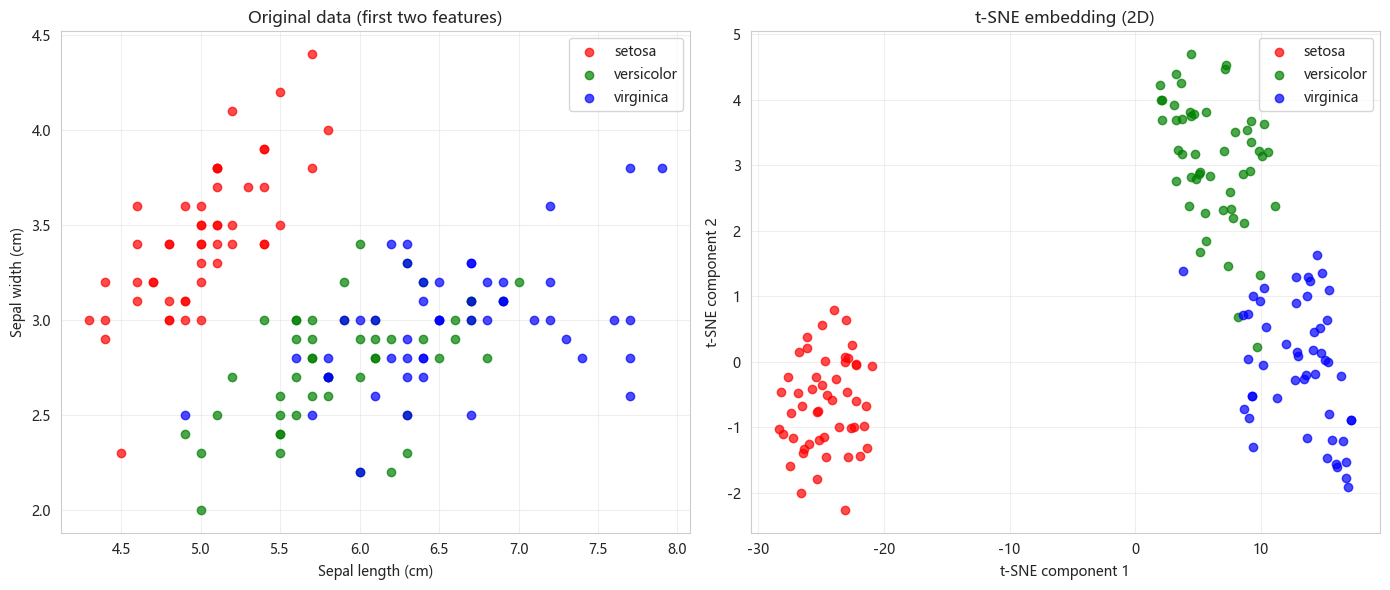

In [26]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.manifold import TSNE

# 加载数据
iris = load_iris()
X = iris.data
y = iris.target

# 创建左右并排的子图
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# ----- 左图：原始数据（前两个特征）-----
colors = ['red', 'green', 'blue']
for i, color in enumerate(colors):
    ax1.scatter(X[y == i, 0], X[y == i, 1], 
                c=color, label=iris.target_names[i], alpha=0.7)
ax1.set_xlabel('Sepal length (cm)')
ax1.set_ylabel('Sepal width (cm)')
ax1.set_title('Original data (first two features)')
ax1.legend()
ax1.grid(alpha=0.3)

# ----- 右图：t-SNE 降维后的 2D 嵌入 -----
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X)

for i, color in enumerate(colors):
    ax2.scatter(X_tsne[y == i, 0], X_tsne[y == i, 1], 
                c=color, label=iris.target_names[i], alpha=0.7)
ax2.set_xlabel('t-SNE component 1')
ax2.set_ylabel('t-SNE component 2')
ax2.set_title('t-SNE embedding (2D)')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("左图 (原始前两维)：仅用花萼长/宽，绿色(Versicolour)与蓝色(Virginica)严重重叠，线性不可分。")
print("右图 (t-SNE降维)：利用全部4个特征进行非线性映射，三类被显著拉开，形成三个独立紧凑的簇。")
print(f"\nt-SNE 参数：perplexity=30, random_state=42")

plt.show()